Load all four Excel files

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project directory
BASE_DIR = r"C:\Users\anush\Desktop\LLMFF\Stockagent"
RES_DIR = os.path.join(BASE_DIR, "res")

# Load the four final Excel files
agent_day_df = pd.read_excel(
    os.path.join(RES_DIR, "agent_day_record.xlsx")
)

agent_session_df = pd.read_excel(
    os.path.join(RES_DIR, "agent_session_record.xlsx")
)

stocks_df = pd.read_excel(
    os.path.join(RES_DIR, "stocks.xlsx")
)

trades_df = pd.read_excel(
    os.path.join(RES_DIR, "trades.xlsx")
)

# Translate column names into English
agent_day_df.rename(columns={
    "交易员": "Agent",
    "交易日": "Day",
    "是否贷款": "Took_Loan",
    "贷款类型": "Loan_Type",
    "贷款数量": "Loan_Amount",
    "明日是否贷款": "Tomorrow_Loan",
    "明日是否买入A": "Tomorrow_Buy_A",
    "明日是否卖出A": "Tomorrow_Sell_A",
    "明日是否买入B": "Tomorrow_Buy_B",
    "明日是否卖出B": "Tomorrow_Sell_B"
}, inplace=True)

agent_session_df.rename(columns={
    "交易员": "Agent",
    "交易日": "Day",
    "交易阶段": "Session",
    "交易前资产总额": "Total_Assets_Before",
    "交易前持有现金": "Cash_Before",
    "交易前持有的A股价值": "Stock_A_Value_Before",
    "交易前持有的B股价值": "Stock_B_Value_Before",
    "挂单类型": "Order_Type",
    "挂单股票类别": "Stock_Type",
    "挂单数量": "Order_Quantity",
    "挂单价格": "Order_Price"
}, inplace=True)

stocks_df.rename(columns={
    "交易日": "Day",
    "第几个交易阶段": "Session",
    "阶段结束后股票A价格": "Stock_A_Price",
    "阶段结束后股票B价格": "Stock_B_Price"
}, inplace=True)

trades_df.rename(columns={
    "交易日": "Day",
    "交易阶段": "Session",
    "股票类型": "Stock_Type",
    "买入交易员": "Buyer_Agent",
    "卖出交易员": "Seller_Agent",
    "交易数量": "Quantity",
    "交易价格": "Trade_Price"
}, inplace=True)

# Dataset overview
datasets = {
    "Daily Records": agent_day_df,
    "Session Records": agent_session_df,
    "Stock Prices": stocks_df,
    "Executed Trades": trades_df
}

print("=" * 60)
print("RQ1 ANALYSIS — DATASET OVERVIEW")
print("=" * 60)

for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Missing values:", df.isna().sum().sum())
    print("Columns:", list(df.columns))

print("\nExpected simulation configuration:")
print("Agents:", 15)
print("Trading days:", 5)
print("Sessions per day:", 3)

print("\nActual unique agents in session records:",
      agent_session_df["Agent"].nunique())

print("Actual unique days in session records:",
      agent_session_df["Day"].nunique())

print("Actual unique sessions:",
      agent_session_df["Session"].nunique())

print("Executed trades recorded:", len(trades_df))

RQ1 ANALYSIS — DATASET OVERVIEW

Daily Records
----------------------------------------
Rows: 75
Columns: 10
Missing values: 0
Columns: ['Agent', 'Day', 'Took_Loan', 'Loan_Type', 'Loan_Amount', 'Tomorrow_Loan', 'Tomorrow_Buy_A', 'Tomorrow_Sell_A', 'Tomorrow_Buy_B', 'Tomorrow_Sell_B']

Session Records
----------------------------------------
Rows: 225
Columns: 11
Missing values: 0
Columns: ['Agent', 'Day', 'Session', 'Total_Assets_Before', 'Cash_Before', 'Stock_A_Value_Before', 'Stock_B_Value_Before', 'Order_Type', 'Stock_Type', 'Order_Quantity', 'Order_Price']

Stock Prices
----------------------------------------
Rows: 15
Columns: 4
Missing values: 0
Columns: ['Day', 'Session', 'Stock_A_Price', 'Stock_B_Price']

Executed Trades
----------------------------------------
Rows: 1
Columns: 7
Missing values: 0
Columns: ['Day', 'Session', 'Stock_Type', 'Buyer_Agent', 'Seller_Agent', 'Quantity', 'Trade_Price']

Expected simulation configuration:
Agents: 15
Trading days: 5
Sessions per day: 3


Data Validation and Consistency Checks

In [2]:
# CELL 2: DATA VALIDATION AND CONSISTENCY CHECKS

print("=" * 70)
print("RQ1 ANALYSIS — DATA VALIDATION")
print("=" * 70)

# 1. Expected versus actual record counts
expected_rows = {
    "Daily Records": 75,
    "Session Records": 225,
    "Stock Prices": 15
}

for name, expected in expected_rows.items():
    actual = len(datasets[name])
    status = "PASS" if actual == expected else "CHECK"
    print(f"{name}: Expected={expected}, Actual={actual} [{status}]")

print(f"Executed Trades: {len(trades_df)} records")

# 2. Missing values
print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    print(f"\n{name}:")
    if missing.empty:
        print("No missing values.")
    else:
        print(missing.to_string())

# 3. Duplicate rows
print("\n" + "=" * 70)
print("DUPLICATE RECORDS")
print("=" * 70)

for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

# 4. Agent IDs and trading days
print("\n" + "=" * 70)
print("AGENT AND DAY CONSISTENCY")
print("=" * 70)

for name in ["Daily Records", "Session Records"]:
    df = datasets[name]

    print(f"\n{name}")
    print("Agent IDs:", sorted(df["Agent"].dropna().unique()))
    print("Day IDs:", sorted(df["Day"].dropna().unique()))
    print("Unique agents:", df["Agent"].nunique())
    print("Unique days:", df["Day"].nunique())

# 5. Session coverage
print("\n" + "=" * 70)
print("SESSION COVERAGE")
print("=" * 70)

print("Sessions recorded:", sorted(agent_session_df["Session"].dropna().unique()))
print("\nRecords per session:")
print(agent_session_df["Session"].value_counts().sort_index())

print("\nRecords per day:")
print(agent_session_df["Day"].value_counts().sort_index())

print("\nRecords per agent:")
print(agent_session_df["Agent"].value_counts().sort_index())

# 6. Stock-price data
print("\n" + "=" * 70)
print("STOCK PRICE VALIDATION")
print("=" * 70)

print(stocks_df[["Day", "Session", "Stock_A_Price", "Stock_B_Price"]]
      .sort_values(["Day", "Session"])
      .to_string(index=False))

print("\nNon-positive stock prices:")
print("Stock A:", (stocks_df["Stock_A_Price"] <= 0).sum())
print("Stock B:", (stocks_df["Stock_B_Price"] <= 0).sum())

# 7. Trade data
print("\n" + "=" * 70)
print("EXECUTED TRADE VALIDATION")
print("=" * 70)

if trades_df.empty:
    print("No executed trades recorded.")
else:
    print("Trade records:", len(trades_df))
    print("Total traded quantity:", trades_df["Quantity"].sum())
    print("Unique buyers:", trades_df["Buyer_Agent"].nunique())
    print("Unique sellers:", trades_df["Seller_Agent"].nunique())
    print("Missing trade values:", trades_df.isnull().sum().sum())

    print("\nTrade records:")
    print(trades_df.to_string(index=False))

print("\nData validation completed.")

RQ1 ANALYSIS — DATA VALIDATION
Daily Records: Expected=75, Actual=75 [PASS]
Session Records: Expected=225, Actual=225 [PASS]
Stock Prices: Expected=15, Actual=15 [PASS]
Executed Trades: 1 records

MISSING VALUES

Daily Records:
No missing values.

Session Records:
No missing values.

Stock Prices:
No missing values.

Executed Trades:
No missing values.

DUPLICATE RECORDS
Daily Records: 0 duplicate rows
Session Records: 0 duplicate rows
Stock Prices: 0 duplicate rows
Executed Trades: 0 duplicate rows

AGENT AND DAY CONSISTENCY

Daily Records
Agent IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Day IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
Unique agents: 5
Unique days: 15

Session Records
Agent IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), 

Stock Price Analysis and Visualization

RQ1 ANALYSIS — STOCK PRICE MOVEMENT

Stock price records:
 Day  Session  Stock_A_Price  Stock_B_Price  Stock_A_Change  Stock_B_Change  Stock_A_Return_%  Stock_B_Return_%
   1        1         26.785         42.225             NaN             NaN               NaN               NaN
   1        2         26.785         42.225             0.0           0.000               0.0            0.0000
   1        3         26.785         42.225             0.0           0.000               0.0            0.0000
   2        1         26.785         42.500             0.0           0.275               0.0            0.6513
   2        2         26.785         42.500             0.0           0.000               0.0            0.0000
   2        3         26.785         42.500             0.0           0.000               0.0            0.0000
   3        1         26.785         42.500             0.0           0.000               0.0            0.0000
   3        2         26.785         42.500   

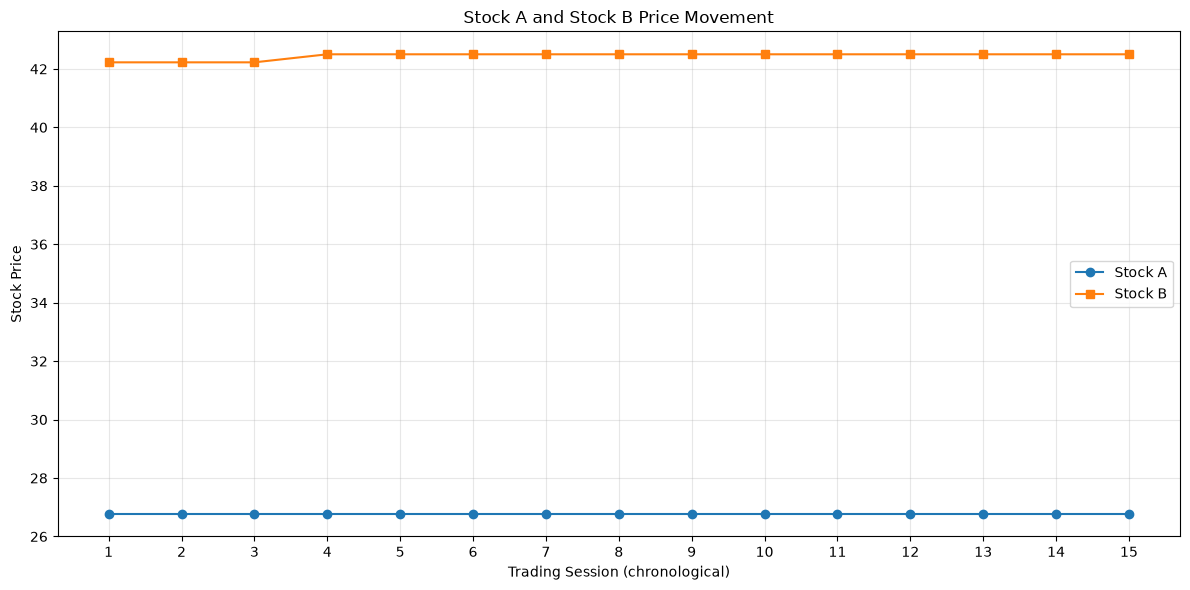

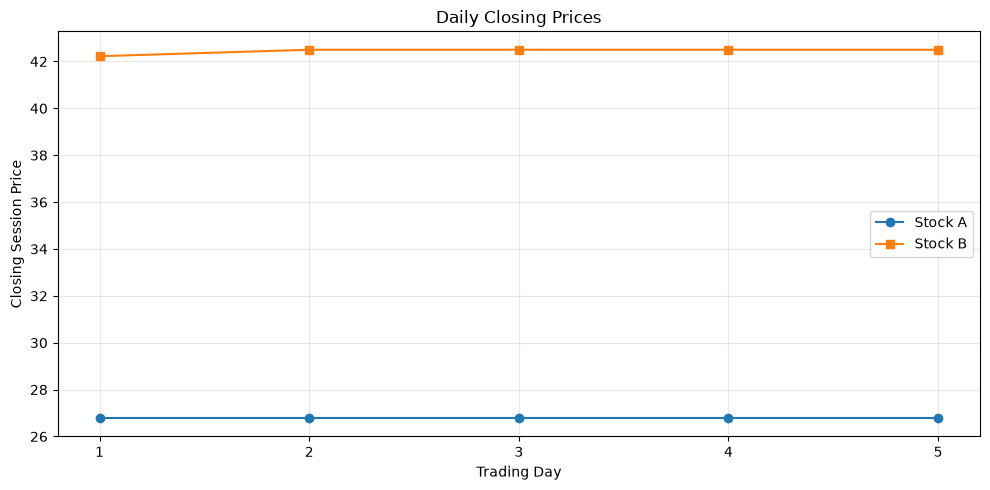

In [3]:
# CELL 3: STOCK PRICE ANALYSIS

print("=" * 60)
print("RQ1 ANALYSIS — STOCK PRICE MOVEMENT")
print("=" * 60)

# Sort records chronologically
stocks_sorted = stocks_df.sort_values(
    ["Day", "Session"]
).copy()

# Calculate price changes between consecutive sessions
stocks_sorted["Stock_A_Change"] = (
    stocks_sorted["Stock_A_Price"].diff()
)

stocks_sorted["Stock_B_Change"] = (
    stocks_sorted["Stock_B_Price"].diff()
)

# Calculate percentage returns
stocks_sorted["Stock_A_Return_%"] = (
    stocks_sorted["Stock_A_Price"].pct_change() * 100
)

stocks_sorted["Stock_B_Return_%"] = (
    stocks_sorted["Stock_B_Price"].pct_change() * 100
)

# Display price movement
print("\nStock price records:")
print(
    stocks_sorted[
        [
            "Day",
            "Session",
            "Stock_A_Price",
            "Stock_B_Price",
            "Stock_A_Change",
            "Stock_B_Change",
            "Stock_A_Return_%",
            "Stock_B_Return_%"
        ]
    ].round(4).to_string(index=False)
)

# Calculate summary statistics
print("\n" + "=" * 60)
print("PRICE SUMMARY")
print("=" * 60)

for stock_name, column in [
    ("Stock A", "Stock_A_Price"),
    ("Stock B", "Stock_B_Price")
]:
    prices = stocks_sorted[column]

    print(f"\n{stock_name}")
    print(f"Opening recorded price: {prices.iloc[0]:.3f}")
    print(f"Closing recorded price: {prices.iloc[-1]:.3f}")
    print(f"Minimum price: {prices.min():.3f}")
    print(f"Maximum price: {prices.max():.3f}")
    print(f"Absolute change: {prices.iloc[-1] - prices.iloc[0]:.3f}")

    if prices.iloc[0] != 0:
        total_return = (
            (prices.iloc[-1] - prices.iloc[0])
            / prices.iloc[0]
        ) * 100
        print(f"Total percentage change: {total_return:.4f}%")

# Plot 1: Stock prices across trading sessions
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(stocks_sorted) + 1),
    stocks_sorted["Stock_A_Price"],
    marker="o",
    label="Stock A"
)

plt.plot(
    range(1, len(stocks_sorted) + 1),
    stocks_sorted["Stock_B_Price"],
    marker="s",
    label="Stock B"
)

plt.xlabel("Trading Session (chronological)")
plt.ylabel("Stock Price")
plt.title("Stock A and Stock B Price Movement")
plt.xticks(range(1, len(stocks_sorted) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Price movement by trading day
daily_prices = (
    stocks_sorted.groupby("Day")[
        ["Stock_A_Price", "Stock_B_Price"]
    ]
    .last()
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    daily_prices["Day"],
    daily_prices["Stock_A_Price"],
    marker="o",
    label="Stock A"
)

plt.plot(
    daily_prices["Day"],
    daily_prices["Stock_B_Price"],
    marker="s",
    label="Stock B"
)

plt.xlabel("Trading Day")
plt.ylabel("Closing Session Price")
plt.title("Daily Closing Prices")
plt.xticks(daily_prices["Day"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Trading Activity Analysis

In [4]:
# CELL 4: TRADING ACTIVITY ANALYSIS

print("=" * 60)
print("RQ1 ANALYSIS — TRADING ACTIVITY")
print("=" * 60)

print(f"\nTotal executed trades: {len(trades_df)}")

if len(trades_df) > 0:

    print("\nTrades by stock:")
    print(trades_df["Stock_Type"].value_counts().to_string())

    print("\nTrades by trading day:")
    print(trades_df["Day"].value_counts().sort_index().to_string())

    print("\nTrades by session:")
    print(trades_df["Session"].value_counts().sort_index().to_string())

    print("\nTrade details:")
    display(
        trades_df[
            [
                "Day",
                "Session",
                "Stock_Type",
                "Buyer_Agent",
                "Seller_Agent",
                "Quantity",
                "Trade_Price"
            ]
        ]
    )

    print("\nTrade statistics:")
    print(f"Total shares traded: {trades_df['Quantity'].sum()}")
    print(f"Average trade quantity: {trades_df['Quantity'].mean():.2f}")
    print(f"Average trade price: {trades_df['Trade_Price'].mean():.3f}")
    print(f"Minimum trade price: {trades_df['Trade_Price'].min():.3f}")
    print(f"Maximum trade price: {trades_df['Trade_Price'].max():.3f}")

    print(
        f"\nTotal transaction value: "
        f"{(trades_df['Quantity'] * trades_df['Trade_Price']).sum():.2f}"
    )

else:
    print("\nNo executed trades were recorded.")

RQ1 ANALYSIS — TRADING ACTIVITY

Total executed trades: 1

Trades by stock:
Stock_Type
B    1

Trades by trading day:
Day
2    1

Trades by session:
Session
1    1

Trade details:


,Day,Session,Stock_Type,Buyer_Agent,Seller_Agent,Quantity,Trade_Price
0,2,1,B,8,11,500,42.5



Trade statistics:
Total shares traded: 500
Average trade quantity: 500.00
Average trade price: 42.500
Minimum trade price: 42.500
Maximum trade price: 42.500

Total transaction value: 21250.00


Agent Trading Behavior

In [7]:
# CELL 5: AGENT ORDER BEHAVIOR ANALYSIS

print("=" * 60)
print("RQ1 ANALYSIS — AGENT ORDER BEHAVIOR")
print("=" * 60)

print(f"\nTotal recorded agent orders: {len(agent_session_df)}")

print("\n1. Orders by type:")
print(
    agent_session_df["Order_Type"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n2. Orders by stock:")
print(
    agent_session_df["Stock_Type"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n3. Orders by trading day:")
print(
    agent_session_df.groupby("Day")
    .size()
    .rename("Number_of_Orders")
    .to_string()
)

print("\n4. Orders by session:")
print(
    agent_session_df.groupby("Session")
    .size()
    .rename("Number_of_Orders")
    .to_string()
)

print("\n5. Order type by stock:")
display(
    pd.crosstab(
        agent_session_df["Order_Type"],
        agent_session_df["Stock_Type"],
        margins=True,
        dropna=False
    )
)

print("\n6. Order price summary:")
print(
    agent_session_df["Order_Price"]
    .describe()
    .round(3)
    .to_string()
)

print("\n7. Order quantity summary:")
print(
    agent_session_df["Order_Quantity"]
    .describe()
    .round(3)
    .to_string()
)

print("\n8. Orders submitted by each agent:")
display(
    agent_session_df.groupby(["Agent", "Order_Type"])
    .size()
    .unstack(fill_value=0)
)

RQ1 ANALYSIS — AGENT ORDER BEHAVIOR

Total recorded agent orders: 225

1. Orders by type:
Order_Type
sell    223
no        1
buy       1

2. Orders by stock:
Stock_Type
A    222
B      2
-      1

3. Orders by trading day:
Day
1    45
2    45
3    45
4    45
5    45

4. Orders by session:
Session
1    75
2    75
3    75

5. Order type by stock:


Stock_Type,-,A,B,All
Order_Type,,,,
buy,0,0,1,1
no,1,0,0,1
sell,0,222,1,223
All,1,222,2,225



6. Order price summary:
count    225.000
mean      26.747
std        2.329
min        0.000
25%       26.780
50%       26.780
75%       26.780
max       42.500

7. Order quantity summary:
count       225.000
mean      55205.244
std       34624.109
min           0.000
25%       20391.000
50%       61283.000
75%       85305.000
max      109598.000

8. Orders submitted by each agent:


Order_Type,buy,no,sell
Agent,,,
0,0,0,15
1,0,0,15
2,0,0,15
3,0,0,15
4,0,0,15
5,0,0,15
6,0,0,15
7,0,0,15
8,1,0,14


Agent Wealth and Portfolio Analysis

In [8]:
# CELL 6: AGENT FINANCIAL POSITION ANALYSIS

print("=" * 60)
print("RQ1 ANALYSIS — AGENT FINANCIAL POSITIONS")
print("=" * 60)

# Summary of financial positions
financial_columns = [
    "Total_Assets_Before",
    "Cash_Before",
    "Stock_A_Value_Before",
    "Stock_B_Value_Before"
]

print("\n1. Overall financial summary:")
display(agent_session_df[financial_columns].describe().round(2))

# Average financial position by agent
print("\n2. Average financial position by agent:")
agent_finances = (
    agent_session_df.groupby("Agent")[financial_columns]
    .mean()
    .round(2)
)

display(agent_finances)

# Financial position by day
print("\n3. Average financial position by day:")
daily_finances = (
    agent_session_df.groupby("Day")[financial_columns]
    .mean()
    .round(2)
)

display(daily_finances)

# Financial position by session
print("\n4. Average financial position by session:")
session_finances = (
    agent_session_df.groupby("Session")[financial_columns]
    .mean()
    .round(2)
)

display(session_finances)

# Check whether recorded total assets match component values
print("\n5. Asset consistency check:")

agent_session_df["Calculated_Assets"] = (
    agent_session_df["Cash_Before"]
    + agent_session_df["Stock_A_Value_Before"]
    + agent_session_df["Stock_B_Value_Before"]
)

agent_session_df["Asset_Difference"] = (
    agent_session_df["Total_Assets_Before"]
    - agent_session_df["Calculated_Assets"]
)

print(
    "Mean absolute difference:",
    round(agent_session_df["Asset_Difference"].abs().mean(), 2)
)

print(
    "Maximum absolute difference:",
    round(agent_session_df["Asset_Difference"].abs().max(), 2)
)

print(
    "Rows with difference above 1:",
    int((agent_session_df["Asset_Difference"].abs() > 1).sum())
)

RQ1 ANALYSIS — AGENT FINANCIAL POSITIONS

1. Overall financial summary:


,Total_Assets_Before,Cash_Before,Stock_A_Value_Before,Stock_B_Value_Before
count,225.00,225.00,225.00,225.00
mean,5979218.08,3657258.09,1491837.00,830122.99
std,1635861.74,2057142.67,921084.82,901354.79
min,3637998.99,396454.21,61043.01,20774.70
25%,4600958.63,1809517.31,546172.93,106632.50
50%,5826723.74,3609842.33,1641465.16,640390.00
75%,7201410.38,5250553.12,2284894.42,919111.57
max,9134378.48,7865051.11,2935582.43,3164848.20



2. Average financial position by agent:


,Total_Assets_Before,Cash_Before,Stock_A_Value_Before,Stock_B_Value_Before
Agent,,,,
0,5678015.18,3854617.90,1802523.36,20873.92
1,4683069.74,3379797.37,1067167.97,236104.40
2,5663691.54,3730327.28,1876342.82,57021.44
3,6628829.81,3154780.51,2550548.06,923501.25
4,4179990.97,2627688.16,1445854.30,106448.51
5,4138423.40,1214243.96,2284894.42,639285.01
6,7005950.01,4702464.54,546172.93,1757312.53
7,5826619.90,3609842.33,2156701.42,60076.16
8,4596772.98,1793933.97,365668.82,2437170.19



3. Average financial position by day:


,Total_Assets_Before,Cash_Before,Stock_A_Value_Before,Stock_B_Value_Before
Day,,,,
1,5761465.74,3443451.57,1491837.0,826177.16
2,6032311.00,3710709.72,1491837.0,829764.28
3,6034104.56,3710709.72,1491837.0,831557.83
4,6034104.56,3710709.72,1491837.0,831557.83
5,6034104.56,3710709.72,1491837.0,831557.83



4. Average financial position by session:


,Total_Assets_Before,Cash_Before,Stock_A_Value_Before,Stock_B_Value_Before
Session,,,,
1,5978500.66,3657258.09,1491837.0,829405.57
2,5979576.79,3657258.09,1491837.0,830481.70
3,5979576.79,3657258.09,1491837.0,830481.70



5. Asset consistency check:
Mean absolute difference: 0.0
Maximum absolute difference: 0.0
Rows with difference above 1: 0


Trading Activity Across Days and Sessions

In [9]:
# CELL 7: ORDER BEHAVIOR OVER TIME

print("=" * 60)
print("RQ1 ANALYSIS — ORDER BEHAVIOR OVER TIME")
print("=" * 60)

# Order types by day
print("\n1. Order types by day:")
orders_by_day = pd.crosstab(
    agent_session_df["Day"],
    agent_session_df["Order_Type"]
)

display(orders_by_day)

# Order types by session
print("\n2. Order types by session:")
orders_by_session = pd.crosstab(
    agent_session_df["Session"],
    agent_session_df["Order_Type"]
)

display(orders_by_session)

# Stock selection by day
print("\n3. Stock selection by day:")
stocks_by_day = pd.crosstab(
    agent_session_df["Day"],
    agent_session_df["Stock_Type"]
)

display(stocks_by_day)

# Average order price by day, excluding no-order records
print("\n4. Average order price by day:")
valid_orders = agent_session_df[
    (agent_session_df["Order_Type"].isin(["buy", "sell"]))
    & (agent_session_df["Order_Price"] > 0)
]

display(
    valid_orders.groupby("Day")["Order_Price"]
    .agg(["count", "mean", "min", "max"])
    .round(3)
)

# Average order quantity by type
print("\n5. Average order quantity by order type:")
display(
    agent_session_df[
        agent_session_df["Order_Type"].isin(["buy", "sell"])
    ]
    .groupby("Order_Type")["Order_Quantity"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

RQ1 ANALYSIS — ORDER BEHAVIOR OVER TIME

1. Order types by day:


Order_Type,buy,no,sell
Day,,,
1,0,1,44
2,1,0,44
3,0,0,45
4,0,0,45
5,0,0,45



2. Order types by session:


Order_Type,buy,no,sell
Session,,,
1,1,1,73
2,0,0,75
3,0,0,75



3. Stock selection by day:


Stock_Type,-,A,B
Day,,,
1,1,44,0
2,0,43,2
3,0,45,0
4,0,45,0
5,0,45,0



4. Average order price by day:


,count,mean,min,max
Day,,,,
1,44,26.780,26.78,26.78
2,45,27.211,26.50,42.50
3,45,26.780,26.78,26.78
4,45,26.780,26.78,26.78
5,45,26.780,26.78,26.78



5. Average order quantity by order type:


,count,mean,min,max
Order_Type,,,,
buy,1,500.00,500,500
sell,223,55698.12,500,109598


Compare Order Prices with Recorded Stock Prices

In [10]:
# CELL 8: ORDER PRICE VS STOCK PRICE

print("=" * 60)
print("RQ1 ANALYSIS — ORDER PRICES VS STOCK PRICES")
print("=" * 60)

# Prepare stock prices for merging
price_reference = stocks_df[
    ["Day", "Session", "Stock_A_Price", "Stock_B_Price"]
].copy()

# Keep actual buy/sell orders with positive prices
valid_orders = agent_session_df[
    agent_session_df["Order_Type"].isin(["buy", "sell"])
    & (agent_session_df["Order_Price"] > 0)
    & (agent_session_df["Stock_Type"].isin(["A", "B"]))
].copy()

# Merge the recorded prices by day and session
comparison = valid_orders.merge(
    price_reference,
    on=["Day", "Session"],
    how="left"
)

# Select the reference price corresponding to the stock
comparison["Reference_Stock_Price"] = np.where(
    comparison["Stock_Type"] == "A",
    comparison["Stock_A_Price"],
    comparison["Stock_B_Price"]
)

# Calculate the difference
comparison["Price_Difference"] = (
    comparison["Order_Price"] - comparison["Reference_Stock_Price"]
)

comparison["Absolute_Price_Difference"] = (
    comparison["Price_Difference"].abs()
)

print("\n1. Order-price comparison:")
display(
    comparison[
        [
            "Day",
            "Session",
            "Agent",
            "Order_Type",
            "Stock_Type",
            "Order_Price",
            "Reference_Stock_Price",
            "Price_Difference"
        ]
    ].round(4)
)

print("\n2. Summary by stock and order type:")
display(
    comparison.groupby(["Stock_Type", "Order_Type"])[
        ["Order_Price", "Reference_Stock_Price",
         "Absolute_Price_Difference"]
    ].mean().round(4)
)

print("\n3. Overall price difference:")
print(
    "Mean absolute price difference:",
    round(comparison["Absolute_Price_Difference"].mean(), 4)
)

print(
    "Maximum absolute price difference:",
    round(comparison["Absolute_Price_Difference"].max(), 4)
)

RQ1 ANALYSIS — ORDER PRICES VS STOCK PRICES

1. Order-price comparison:


,Day,Session,Agent,Order_Type,Stock_Type,Order_Price,Reference_Stock_Price,Price_Difference
0,1,1,4,sell,A,26.78,26.785,-0.005
1,1,1,0,sell,A,26.78,26.785,-0.005
2,1,1,2,sell,A,26.78,26.785,-0.005
3,1,1,12,sell,A,26.78,26.785,-0.005
4,1,1,13,sell,A,26.78,26.785,-0.005
...,...,...,...,...,...,...,...,...
219,5,3,6,sell,A,26.78,26.785,-0.005
220,5,3,0,sell,A,26.78,26.785,-0.005
221,5,3,2,sell,A,26.78,26.785,-0.005
222,5,3,3,sell,A,26.78,26.785,-0.005



2. Summary by stock and order type:


Order_Price  Reference_Stock_Price  \
Stock_Type Order_Type                                       
A          sell            26.7258                 26.785   
B          buy             42.5000                 42.500   
           sell            42.5000                 42.500   

                       Absolute_Price_Difference  
Stock_Type Order_Type                             
A          sell                           0.0592  
B          buy                            0.0000  
           sell                           0.0000


3. Overall price difference:
Mean absolute price difference: 0.0587
Maximum absolute price difference: 0.285


Final Visualizations

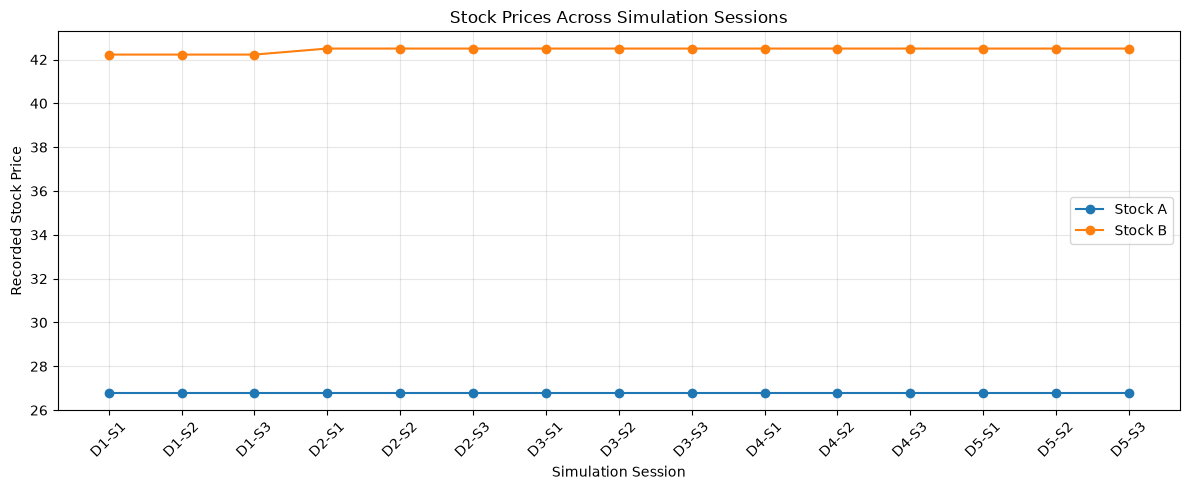

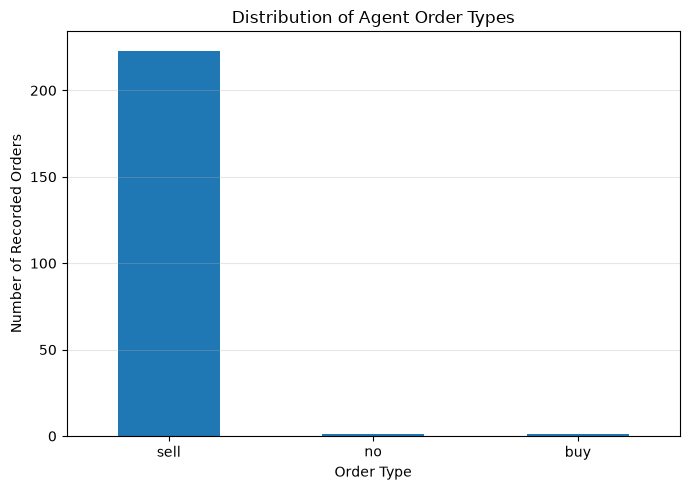

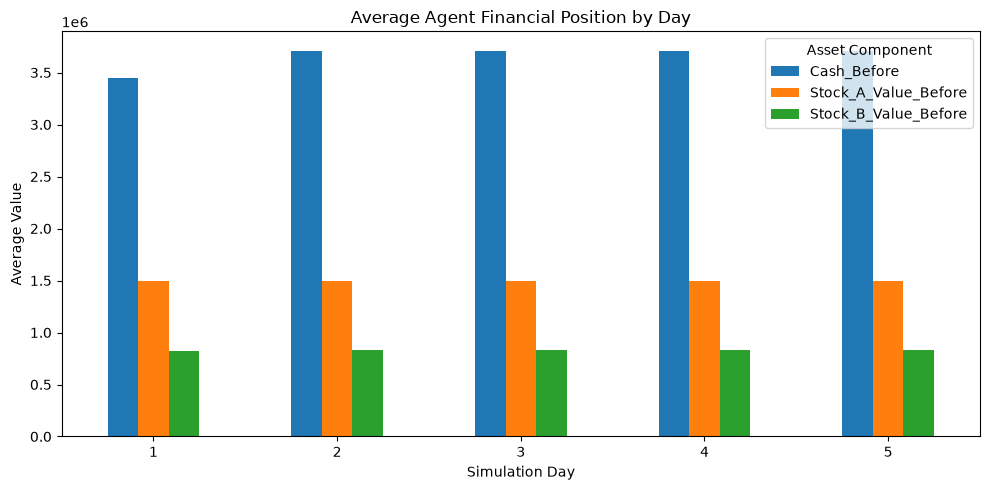

All three RQ1 visualizations generated successfully.


In [11]:
# CELL 9: FINAL RQ1 VISUALIZATIONS

# 1. Stock price movements
stocks_sorted = stocks_df.sort_values(["Day", "Session"]).copy()
stocks_sorted["Period"] = (
    "D" + stocks_sorted["Day"].astype(str)
    + "-S" + stocks_sorted["Session"].astype(str)
)

plt.figure(figsize=(12, 5))
plt.plot(
    stocks_sorted["Period"],
    stocks_sorted["Stock_A_Price"],
    marker="o",
    label="Stock A"
)
plt.plot(
    stocks_sorted["Period"],
    stocks_sorted["Stock_B_Price"],
    marker="o",
    label="Stock B"
)
plt.title("Stock Prices Across Simulation Sessions")
plt.xlabel("Simulation Session")
plt.ylabel("Recorded Stock Price")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Order type distribution
order_counts = agent_session_df["Order_Type"].value_counts()

plt.figure(figsize=(7, 5))
order_counts.plot(kind="bar")
plt.title("Distribution of Agent Order Types")
plt.xlabel("Order Type")
plt.ylabel("Number of Recorded Orders")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Average financial position by day
daily_finances = (
    agent_session_df.groupby("Day")[
        [
            "Cash_Before",
            "Stock_A_Value_Before",
            "Stock_B_Value_Before"
        ]
    ].mean()
)

daily_finances.plot(kind="bar", figsize=(10, 5))
plt.title("Average Agent Financial Position by Day")
plt.xlabel("Simulation Day")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(title="Asset Component")
plt.tight_layout()
plt.show()

print("All three RQ1 visualizations generated successfully.")

Export RQ1 Results

In [12]:
# CELL 10: EXPORT RQ1 ANALYSIS RESULTS

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = os.path.join(BASE_DIR, "analysis_results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

output_file = os.path.join(OUTPUT_DIR, "RQ1_Analysis_Results.xlsx")

# 1. Stock price summary
price_summary = pd.DataFrame([
    {
        "Stock": "Stock A",
        "Opening_Price": stocks_sorted["Stock_A_Price"].iloc[0],
        "Closing_Price": stocks_sorted["Stock_A_Price"].iloc[-1],
        "Minimum_Price": stocks_sorted["Stock_A_Price"].min(),
        "Maximum_Price": stocks_sorted["Stock_A_Price"].max(),
        "Percentage_Change": (
            (stocks_sorted["Stock_A_Price"].iloc[-1]
             / stocks_sorted["Stock_A_Price"].iloc[0] - 1) * 100
        )
    },
    {
        "Stock": "Stock B",
        "Opening_Price": stocks_sorted["Stock_B_Price"].iloc[0],
        "Closing_Price": stocks_sorted["Stock_B_Price"].iloc[-1],
        "Minimum_Price": stocks_sorted["Stock_B_Price"].min(),
        "Maximum_Price": stocks_sorted["Stock_B_Price"].max(),
        "Percentage_Change": (
            (stocks_sorted["Stock_B_Price"].iloc[-1]
             / stocks_sorted["Stock_B_Price"].iloc[0] - 1) * 100
        )
    }
])

# 2. Order type summary
order_summary = (
    agent_session_df["Order_Type"]
    .value_counts(dropna=False)
    .rename_axis("Order_Type")
    .reset_index(name="Count")
)

order_summary["Percentage"] = (
    order_summary["Count"] / len(agent_session_df) * 100
)

# 3. Stock selection summary
stock_summary = (
    agent_session_df["Stock_Type"]
    .value_counts(dropna=False)
    .rename_axis("Stock_Type")
    .reset_index(name="Count")
)

# 4. Financial position by day
financial_by_day = (
    agent_session_df.groupby("Day")[
        [
            "Total_Assets_Before",
            "Cash_Before",
            "Stock_A_Value_Before",
            "Stock_B_Value_Before"
        ]
    ]
    .mean()
    .reset_index()
)

# 5. Order-price comparison summary
price_comparison_summary = (
    comparison.groupby(["Stock_Type", "Order_Type"])
    .agg(
        Number_of_Orders=("Order_Price", "count"),
        Average_Order_Price=("Order_Price", "mean"),
        Average_Reference_Price=("Reference_Stock_Price", "mean"),
        Mean_Absolute_Price_Difference=(
            "Absolute_Price_Difference", "mean"
        )
    )
    .reset_index()
)

# 6. Executed trade summary
trade_summary = pd.DataFrame({
    "Metric": [
        "Total executed trades",
        "Total shares traded",
        "Total transaction value"
    ],
    "Value": [
        len(trades_df),
        trades_df["Quantity"].sum(),
        (trades_df["Quantity"] * trades_df["Trade_Price"]).sum()
    ]
})

# Export tables
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    price_summary.to_excel(
        writer, sheet_name="Stock Prices", index=False
    )
    order_summary.to_excel(
        writer, sheet_name="Order Types", index=False
    )
    stock_summary.to_excel(
        writer, sheet_name="Stock Selection", index=False
    )
    financial_by_day.to_excel(
        writer, sheet_name="Financial Positions", index=False
    )
    price_comparison_summary.to_excel(
        writer, sheet_name="Order Price Comparison", index=False
    )
    trade_summary.to_excel(
        writer, sheet_name="Executed Trades", index=False
    )

print("=" * 60)
print("RQ1 ANALYSIS EXPORT COMPLETED")
print("=" * 60)
print("\nOutput file:")
print(output_file)

print("\nSheets exported:")
print(
    "1. Stock Prices\n"
    "2. Order Types\n"
    "3. Stock Selection\n"
    "4. Financial Positions\n"
    "5. Order Price Comparison\n"
    "6. Executed Trades"
)

print("\nTotal executed trades:", len(trades_df))
print("Total recorded agent-session observations:", len(agent_session_df))

RQ1 ANALYSIS EXPORT COMPLETED

Output file:
C:\Users\anush\Desktop\LLMFF\Stockagent\analysis_results\RQ1_Analysis_Results.xlsx

Sheets exported:
1. Stock Prices
2. Order Types
3. Stock Selection
4. Financial Positions
5. Order Price Comparison
6. Executed Trades

Total executed trades: 1
Total recorded agent-session observations: 225
